<div style="font-family:Times New Roman;font-size:14pt;color:black"><b>Лабораторна робота 3</b><br>Лінійна регресія<br>Виконав Шиндир Олексій<br>4 курс, 10 група</div>

<a href="https://colab.research.google.com/github/raysewww-lang/mashynne-navchannia/blob/main/%D0%A8%D0%B8%D0%BD%D0%B4%D0%B8%D1%80_%D0%BF%D1%80_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Відкрити в Colab"/></a>

In [1]:
# Підготовка бібліотек і даних. Дані автоматично завантажуються з GitHub; резервний спосіб — data.zip.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
np.random.seed(25)
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],'font.size':14,'figure.figsize':(9,5)})
pd.set_option('display.max_columns',40)

def data_path(name):
    for folder in [Path('data'),Path('.'),Path('/content/data'),Path('/content')]:
        p=folder/name
        if p.exists():
            return p
    import zipfile, io
    from urllib.request import urlopen
    try:
        url='https://raw.githubusercontent.com/raysewww-lang/mashynne-navchannia/main/data.zip'
        with urlopen(url, timeout=60) as response:
            content=response.read()
        Path('data').mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for member in z.namelist():
                if not member.endswith('/'):
                    (Path('data')/Path(member).name).write_bytes(z.read(member))
        if (Path('data')/name).exists():
            return Path('data')/name
    except Exception as error:
        print('Автоматичне завантаження недоступне:',error)
    from google.colab import files
    import zipfile, io
    print('Завантажте data.zip або файл',name)
    uploaded=files.upload()
    Path('data').mkdir(exist_ok=True)
    for fname,content in uploaded.items():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                for member in z.namelist():
                    if not member.endswith('/'):
                        (Path('data')/Path(member).name).write_bytes(z.read(member))
        else:
            (Path('data')/Path(fname).name).write_bytes(content)
    p=Path('data')/name
    if not p.exists():
        raise FileNotFoundError(name)
    return p

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Розмір: (442, 11)


age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Дублікати: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


Стать до кодування: [ 0.05068012 -0.04464164]


age       float64
sex         int64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

bmi    0.586450
s5     0.565883
bp     0.441482
s4     0.430453
s6     0.382483
s1     0.212022
age    0.187889
s2     0.174054
sex    0.043062
s3    -0.394789
Name: target, dtype: float64

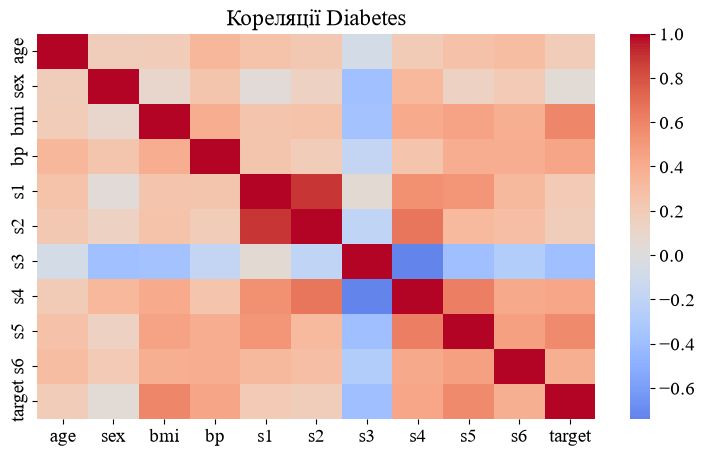

In [2]:
# Завдання 1. Diabetes. Пункти 1–6: завантажити, дослідити пропуски, дублікати, стать, типи та кореляцію.
from sklearn.datasets import load_diabetes
dataset=load_diabetes(as_frame=True)
df=dataset.frame.copy()

display(df.head()); print('Розмір:',df.shape);display(df.dtypes)
display(df.isna().sum());print('Дублікати:',df.duplicated().sum())
df=df.drop_duplicates().copy()
display(df.describe())

print('Стать до кодування:',df.sex.unique())
sex_values=sorted(df.sex.unique())
df['sex']=df.sex.map({sex_values[0]:0,sex_values[1]:1})
display(df.dtypes)
display(df.corr()['target'].drop('target').sort_values(ascending=False))
sns.heatmap(df.corr(),cmap='coolwarm',center=0);plt.title('Кореляції Diabetes');plt.show()

In [3]:
# Завдання 1. Пункти 7–12. Поділ 80/20 та налаштування моделей крос-валідацією. Масштабування всередині Pipeline.
X=df.drop(columns='target');y=df.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=25)
cv=KFold(n_splits=3,shuffle=True,random_state=25)

from sklearn.feature_selection import SelectKBest, f_regression

models={'Лінійна':LinearRegression(),'Випадковий ліс':RandomForestRegressor(random_state=25,n_jobs=1)}
grids={'Лінійна':{'select__k':[3,5,7,10]},'Випадковий ліс':{'select__k':[3,5,7,10],'model__n_estimators':[80],'model__max_depth':[4,None]}}
fitted={}
rows=[]
for name,model in models.items():
    pipe=Pipeline([('imputer',SimpleImputer()),('select',SelectKBest(f_regression)),('scale',StandardScaler()),('model',model)])
    grid=GridSearchCV(pipe,grids[name],cv=cv,scoring='neg_mean_squared_error',n_jobs=1)
    grid.fit(X_train,y_train)
    fitted[name]=grid
    pred=grid.predict(X_test)
    rows.append([name,-grid.best_score_,mean_squared_error(y_test,pred),r2_score(y_test,pred),grid.best_params_])
results=pd.DataFrame(rows,columns=['Модель','CV MSE','Test MSE','Test R2','Параметри'])
display(results)
best_name=results.loc[results['CV MSE'].idxmin(),'Модель']
print('Найкраща за CV:',best_name)

,Модель,CV MSE,Test MSE,Test R2,Параметри
0,Лінійна,3208.287941,2909.488586,0.437300,{'select__k': 10}
1,Випадковий ліс,3337.506295,3488.914878,0.325238,"{'model__max_depth': 4, 'model__n_estimators':..."


Найкраща за CV: Лінійна


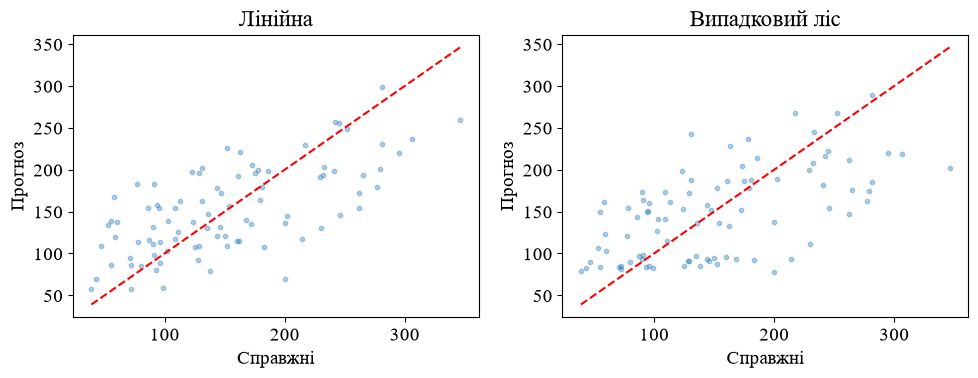

,Справжні,Лінійна,Випадковий ліс
405,281.0,298.090102,288.908162
422,233.0,203.616013,244.684430
95,162.0,114.263547,133.234421
337,91.0,182.836713,163.954067
338,214.0,117.371332,93.663053
134,103.0,138.846080,141.589534
117,281.0,231.019634,185.047364
294,55.0,86.241288,83.547349
401,93.0,79.887838,84.361448
430,183.0,107.087321,92.059198


Висновок за результатами: найкраща CV-модель — Лінійна


,Test MSE,Test R2
0,2909.488586,0.4373


In [4]:
# Завдання 1. Пункти 7–12. Графіки та справжні й прогнозовані значення всіх моделей.
fig,axes=plt.subplots(1,len(fitted),figsize=(5*len(fitted),4),squeeze=False)
for ax,(name,model) in zip(axes.flat,fitted.items()):
    pred=model.predict(X_test)
    ax.scatter(y_test,pred,alpha=0.35,s=10)
    lo,hi=min(y_test.min(),pred.min()),max(y_test.max(),pred.max())
    ax.plot([lo,hi],[lo,hi],'r--');ax.set_title(name);ax.set_xlabel('Справжні');ax.set_ylabel('Прогноз')
plt.tight_layout();plt.show()
comparison=pd.DataFrame({'Справжні':y_test})
for name,model in fitted.items():comparison[name]=model.predict(X_test)
display(comparison.head(20))
print('Висновок за результатами: найкраща CV-модель —',best_name)
display(results.loc[results['Модель']==best_name,['Test MSE','Test R2']])

In [5]:
# Висновок. Завдання 1. Кількість ознак і параметри обрано за CV MSE. Відбір ознак і масштабування виконуються окремо в кожному навчальному фолді. Test R2 та MSE наведені у таблиці; кореляція не гарантує точного прогнозу прогресування діабету.

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Розмір: (20640, 9)


MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Дублікати: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64

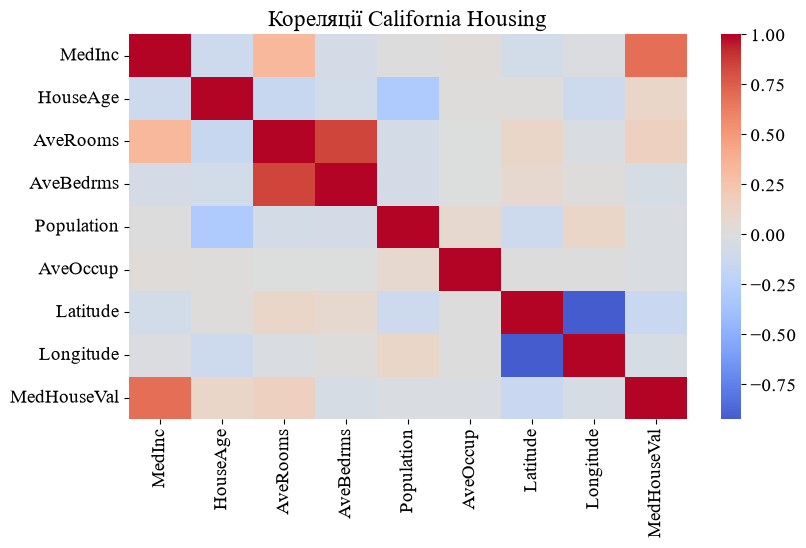

У наборі немає бінарної ознаки статі; перекодування не потрібне.


In [6]:
# Завдання 2. California Housing. Попередній аналіз за схемою завдання 1.
df=pd.read_csv(data_path('california_housing.csv'))

display(df.head()); print('Розмір:',df.shape);display(df.dtypes)
display(df.isna().sum());print('Дублікати:',df.duplicated().sum())
df=df.drop_duplicates().copy()
display(df.describe())

display(df.corr()['MedHouseVal'].sort_values(ascending=False))
sns.heatmap(df.corr(),cmap='coolwarm',center=0);plt.title('Кореляції California Housing');plt.show()
print('У наборі немає бінарної ознаки статі; перекодування не потрібне.')

In [7]:
# Завдання 2. Пункти 2–6. Поділ 80/20 та налаштування моделей крос-валідацією. Масштабування всередині Pipeline.
X=df.drop(columns='MedHouseVal');y=df.MedHouseVal
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=25)
cv=KFold(n_splits=3,shuffle=True,random_state=25)

models={'Лінійна':LinearRegression(),'Випадковий ліс':RandomForestRegressor(random_state=25,n_jobs=1),'Ridge':Ridge()}
grids={'Лінійна':{'model__fit_intercept':[True,False]},'Випадковий ліс':{'model__n_estimators':[60],'model__max_depth':[12,None],'model__min_samples_leaf':[1,3]},'Ridge':{'model__alpha':[0.1,1,10,100]}}
fitted={}
rows=[]
for name,model in models.items():
    pipe=Pipeline([('imputer',SimpleImputer()),('scale',StandardScaler()),('model',model)])
    grid=GridSearchCV(pipe,grids[name],cv=cv,scoring='neg_mean_squared_error',n_jobs=1)
    grid.fit(X_train,y_train)
    fitted[name]=grid
    pred=grid.predict(X_test)
    rows.append([name,-grid.best_score_,mean_squared_error(y_test,pred),r2_score(y_test,pred),grid.best_params_])
results=pd.DataFrame(rows,columns=['Модель','CV MSE','Test MSE','Test R2','Параметри'])
display(results)
best_name=results.loc[results['CV MSE'].idxmin(),'Модель']
print('Найкраща за CV:',best_name)

,Модель,CV MSE,Test MSE,Test R2,Параметри
0,Лінійна,0.529198,0.527930,0.591994,{'model__fit_intercept': True}
1,Випадковий ліс,0.270126,0.231691,0.820940,"{'model__max_depth': None, 'model__min_samples..."
2,Ridge,0.529165,0.527631,0.592225,{'model__alpha': 10}


Найкраща за CV: Випадковий ліс


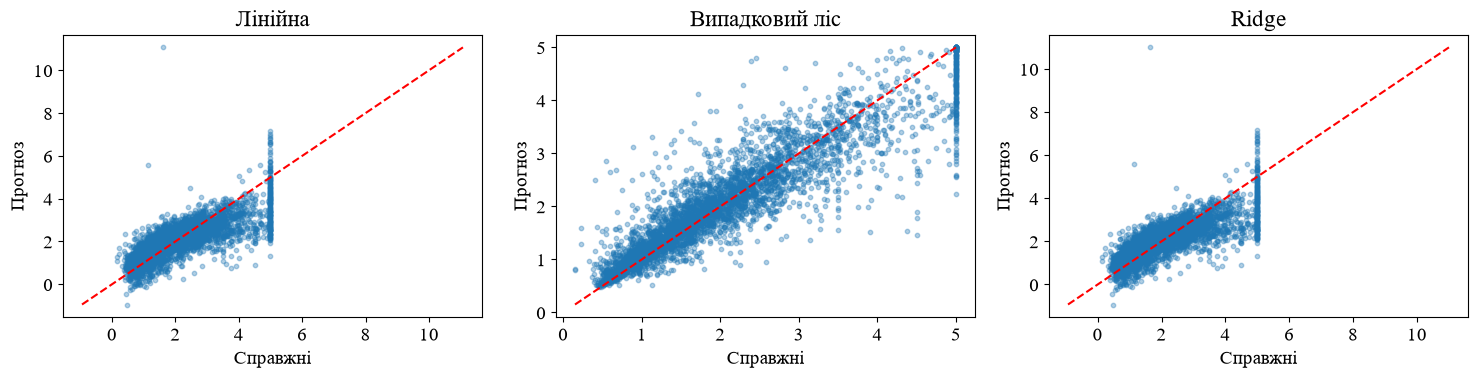

,Справжні,Лінійна,Випадковий ліс,Ridge
73,0.67500,1.063958,2.683187,1.062704
8944,4.61100,2.177164,3.633152,2.175262
3737,2.86000,2.068547,2.834067,2.067258
19092,2.01800,3.019453,2.860567,3.017132
9493,1.51400,1.955985,1.244233,1.952204
14567,1.76000,1.767640,1.651933,1.766962
12480,1.68800,1.133397,1.069283,1.136332
12680,1.26200,1.422542,1.254750,1.425937
20463,2.64400,2.694344,2.448850,2.693784
18995,2.60900,1.940881,1.638183,1.941355


Висновок за результатами: найкраща CV-модель — Випадковий ліс


,Test MSE,Test R2
1,0.231691,0.82094


In [8]:
# Завдання 2. Пункти 2–6. Графіки та справжні й прогнозовані значення всіх моделей.
fig,axes=plt.subplots(1,len(fitted),figsize=(5*len(fitted),4),squeeze=False)
for ax,(name,model) in zip(axes.flat,fitted.items()):
    pred=model.predict(X_test)
    ax.scatter(y_test,pred,alpha=0.35,s=10)
    lo,hi=min(y_test.min(),pred.min()),max(y_test.max(),pred.max())
    ax.plot([lo,hi],[lo,hi],'r--');ax.set_title(name);ax.set_xlabel('Справжні');ax.set_ylabel('Прогноз')
plt.tight_layout();plt.show()
comparison=pd.DataFrame({'Справжні':y_test})
for name,model in fitted.items():comparison[name]=model.predict(X_test)
display(comparison.head(20))
print('Висновок за результатами: найкраща CV-модель —',best_name)
display(results.loc[results['Модель']==best_name,['Test MSE','Test R2']])

In [9]:
# Висновок. Завдання 2. Порівняно лінійну регресію, Random Forest і Ridge на однаковому поділі. Найкращу модель визначено за крос-валідацією, а тестову вибірку використано для остаточної оцінки. Значення цілі подані в сотнях тисяч доларів.